In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, '..')  # the repository root, which holds cpd/

from cpd import dependence
from cpd import methods
from cpd import plotting
from cpd import processes

PLOTS = Path('../figures')  # every figure is also saved here
PLOTS.mkdir(exist_ok=True)

# One look per test in every plot. KS with the true sigma is the dashed black
# reference. Different markers so that curves lying on top of each other can
# be told apart.
STYLE = plotting.TEST_STYLE
plotting.apply_style()

In [2]:
CRIT = methods.CRITICAL_VALUES


def test_stats(x, phi):
    # The true long-run variance of AR(1) with N(0, 1) innovations is used
    # by KS (true sigma).
    return methods.test_statistics(x, dependence.ar1_lrv(phi))


def rejection_rates(phi, n, n_rep, rng):
    x = processes.simulate_ar1(phi, n, n_rep, rng)
    return methods.rejection_rates(test_stats(x, phi))


rng = np.random.default_rng(2026)
rejection_rates(0.0, 200, 2000, rng)

{'FB': 0.027,
 'DDB1': 0.0345,
 'DDB2': 0.0465,
 'DDB-JX': 0.0365,
 'SN': 0.0455,
 'KS (true sigma)': 0.033}

In [3]:
phis = [-0.5, -0.2, 0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
ns = [200, 500]
tests = list(methods.METHODS)
n_rep = 5000

size = {}
for n in ns:
    size[n] = [rejection_rates(phi, n, n_rep, rng) for phi in phis]

width = {m: max(8, len(m) + 2) for m in tests}
for n in ns:
    print(f'n = {n}, rejection rate in %')
    print('  phi' + ''.join(f'{m:>{width[m]}}' for m in tests))
    for phi, r in zip(phis, size[n]):
        print(f'{phi:5.1f}'
              + ''.join(f'{100 * r[m]:{width[m]}.1f}' for m in tests))
    print()

n = 200, rejection rate in %
  phi      FB    DDB1    DDB2  DDB-JX      SN  KS (true sigma)
 -0.5     1.6     1.8     5.4     4.3     4.4              5.6
 -0.2     2.4     2.5     4.4     3.6     4.6              4.3
  0.0     3.0     3.8     5.1     4.0     5.3              4.0
  0.2     3.8     5.3     8.6     5.0     4.9              3.1
  0.4     4.7     4.7    11.1     4.8     5.8              2.9
  0.5     6.6     5.3    13.1     5.5     6.0              3.3
  0.6     7.6     4.2    14.2     4.8     6.6              2.3
  0.7    12.3     4.0    18.7     5.4     8.1              2.5
  0.8    20.1     2.9    22.6     5.8     8.3              2.0
  0.9    42.3     0.7    34.0     5.8    13.6              0.7

n = 500, rejection rate in %
  phi      FB    DDB1    DDB2  DDB-JX      SN  KS (true sigma)
 -0.5     2.2     2.5     4.5     4.4     4.8              4.9
 -0.2     2.8     2.6     3.6     3.4     4.8              4.4
  0.0     4.0     4.3     4.9     4.5     5.3              

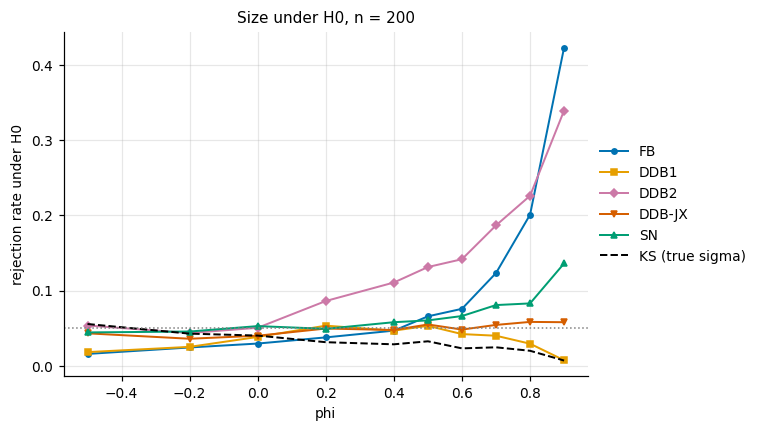

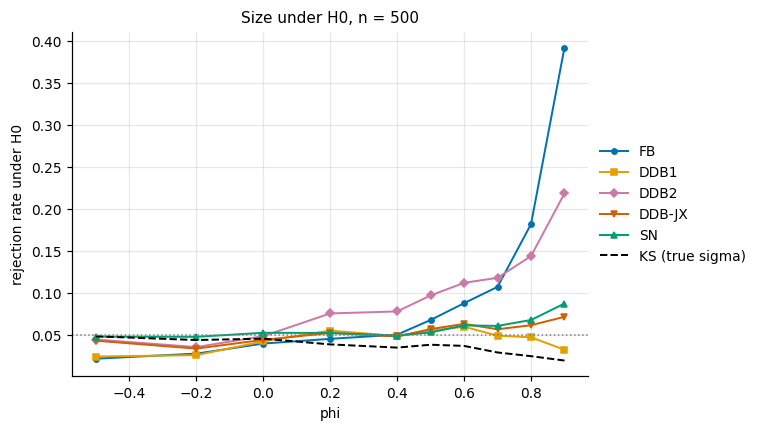

In [4]:
for n in ns:
    fig, ax = plt.subplots(figsize=(7, 4))
    for m in tests:
        ax.plot(phis, [r[m] for r in size[n]], label=m, **STYLE[m])
    ax.axhline(0.05, color='gray', ls=':', lw=1)
    ax.set_title(f'Size under H0, n = {n}')
    ax.set_xlabel('phi')
    ax.set_ylabel('rejection rate under H0')
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    fig.savefig(PLOTS / f'size_under_H0_n{n}.png')
    plt.show()

In [5]:
# Table 2 of the paper, sizes in % for phi = 0, 0.5, 0.8.
paper = {
    200: {'FB': [3.5, 6.9, 20.2], 'DDB1': [2.5, 4.9, 2.4],
          'DDB2': [4.1, 12.8, 22.8], 'DDB-JX': [4.2, 6.0, 5.8],
          'SN': [4.9, 6.1, 8.6]},
    500: {'FB': [3.6, 6.2, 18.4], 'DDB1': [2.7, 4.7, 4.5],
          'DDB2': [3.4, 8.8, 14.1], 'DDB-JX': [4.1, 5.1, 6.0],
          'SN': [5.2, 5.3, 6.5]},
}

print('mine / paper')
for n in ns:
    for i, phi in enumerate([0.0, 0.5, 0.8]):
        r = size[n][phis.index(phi)]
        cells = [f'{m} {100 * r[m]:4.1f} / {paper[n][m][i]:4.1f}'
                 for m in paper[n]]
        print(f'n = {n}, phi = {phi}:   ' + '   '.join(cells))

mine / paper
n = 200, phi = 0.0:   FB  3.0 /  3.5   DDB1  3.8 /  2.5   DDB2  5.1 /  4.1   DDB-JX  4.0 /  4.2   SN  5.3 /  4.9
n = 200, phi = 0.5:   FB  6.6 /  6.9   DDB1  5.3 /  4.9   DDB2 13.1 / 12.8   DDB-JX  5.5 /  6.0   SN  6.0 /  6.1
n = 200, phi = 0.8:   FB 20.1 / 20.2   DDB1  2.9 /  2.4   DDB2 22.6 / 22.8   DDB-JX  5.8 /  5.8   SN  8.3 /  8.6
n = 500, phi = 0.0:   FB  4.0 /  3.6   DDB1  4.3 /  2.7   DDB2  4.9 /  3.4   DDB-JX  4.5 /  4.1   SN  5.3 /  5.2
n = 500, phi = 0.5:   FB  6.8 /  6.2   DDB1  5.6 /  4.7   DDB2  9.7 /  8.8   DDB-JX  5.7 /  5.1   SN  5.3 /  5.3
n = 500, phi = 0.8:   FB 18.2 / 18.4   DDB1  4.8 /  4.5   DDB2 14.4 / 14.1   DDB-JX  6.2 /  6.0   SN  6.8 /  6.5


In [6]:
power_phis = [0.0, 0.5, 0.8]
# The paper stops at eta = 6, but DDB1's power often collapses only later.
etas = np.arange(0, 12.01, 0.1)
n_rep_power = 2000

raw_power = {}
power = {}  # size-adjusted
adj_crit = {}
for n in ns:
    jump = (np.arange(1, n + 1) > n / 2).astype(float)
    for phi in power_phis:
        null = test_stats(processes.simulate_ar1(phi, n, n_rep, rng), phi)
        crit = {m: np.quantile(null[m], 0.95) for m in tests}
        adj_crit[n, phi] = crit
        u = processes.simulate_ar1(phi, n, n_rep_power, rng)
        raw = {m: [] for m in tests}
        adj = {m: [] for m in tests}
        for eta in etas:
            stats = test_stats(eta * jump + u, phi)
            for m in tests:
                raw[m].append(np.mean(stats[m] > CRIT[m]))
                adj[m].append(np.mean(stats[m] > crit[m]))
        raw_power[n, phi] = raw
        power[n, phi] = adj

print('size-adjusted critical values (asymptotic: KS 1.358, SN 40.1)')
for (n, phi), crit in adj_crit.items():
    vals = '   '.join(f'{m} {crit[m]:6.2f}' for m in tests)
    print(f'n = {n}, phi = {phi}:   {vals}')

size-adjusted critical values (asymptotic: KS 1.358, SN 40.1)
n = 200, phi = 0.0:   FB   1.30   DDB1   1.31   DDB2   1.36   DDB-JX   1.32   SN  41.71   KS (true sigma)   1.32
n = 200, phi = 0.5:   FB   1.40   DDB1   1.35   DDB2   1.61   DDB-JX   1.36   SN  44.99   KS (true sigma)   1.28
n = 200, phi = 0.8:   FB   1.68   DDB1   1.29   DDB2   1.91   DDB-JX   1.37   SN  53.17   KS (true sigma)   1.18
n = 500, phi = 0.0:   FB   1.31   DDB1   1.33   DDB2   1.35   DDB-JX   1.34   SN  41.30   KS (true sigma)   1.32
n = 500, phi = 0.5:   FB   1.41   DDB1   1.37   DDB2   1.51   DDB-JX   1.38   SN  41.70   KS (true sigma)   1.31
n = 500, phi = 0.8:   FB   1.68   DDB1   1.35   DDB2   1.68   DDB-JX   1.41   SN  46.46   KS (true sigma)   1.26


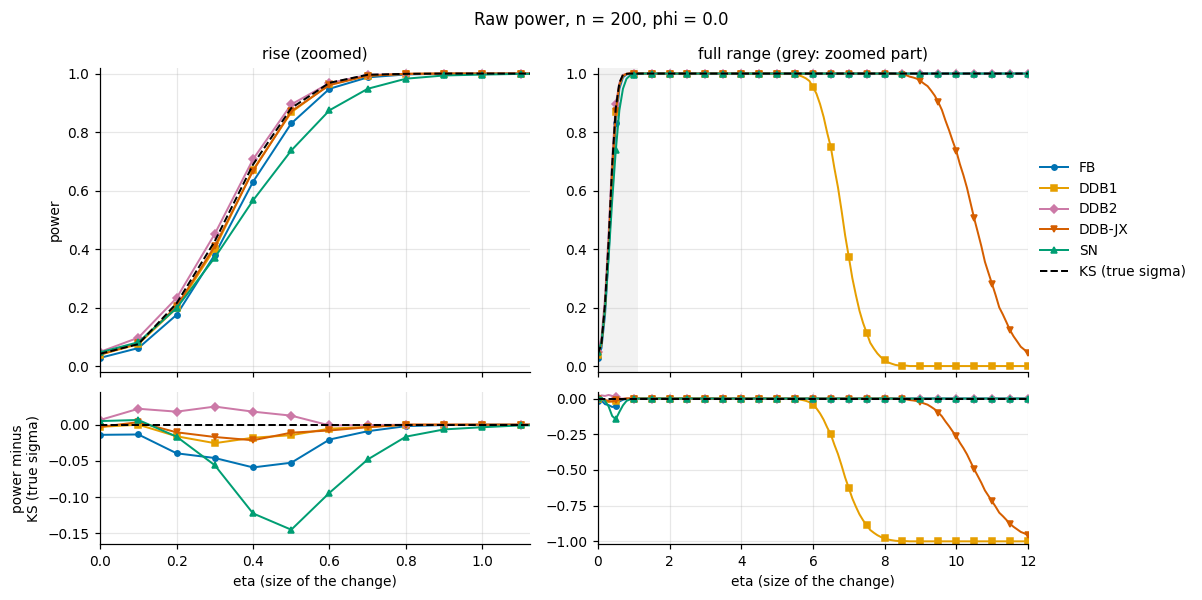

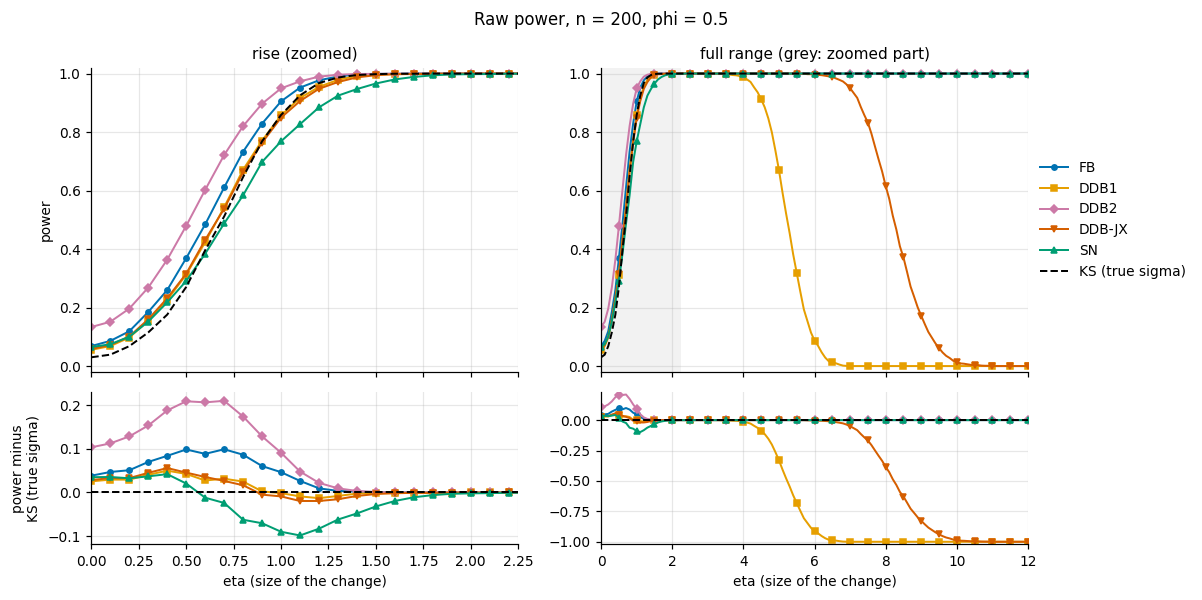

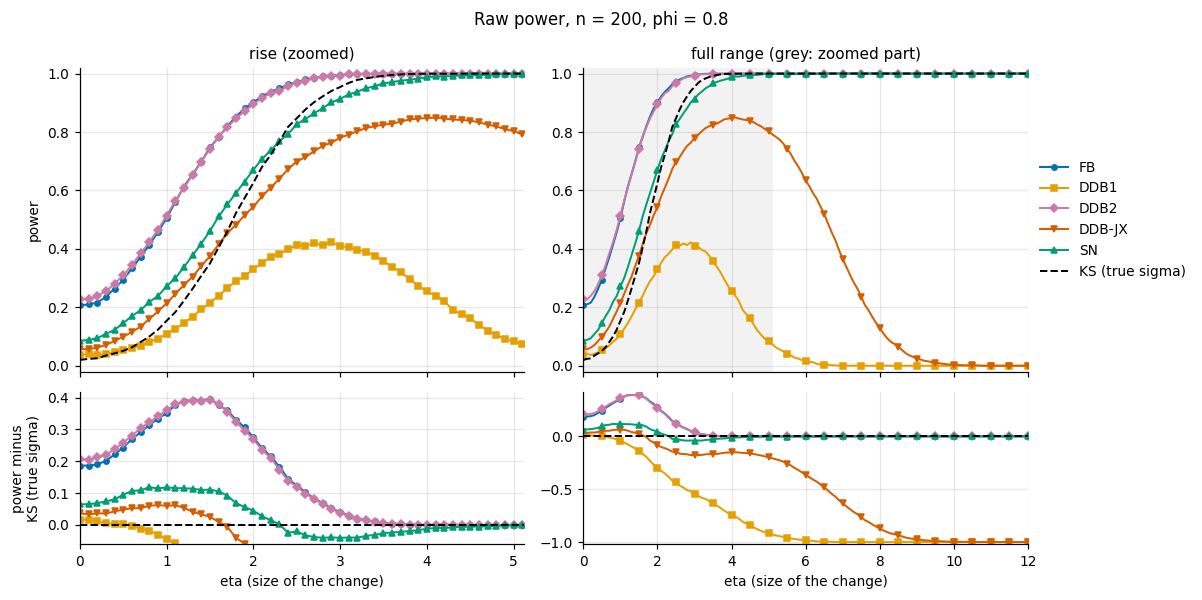

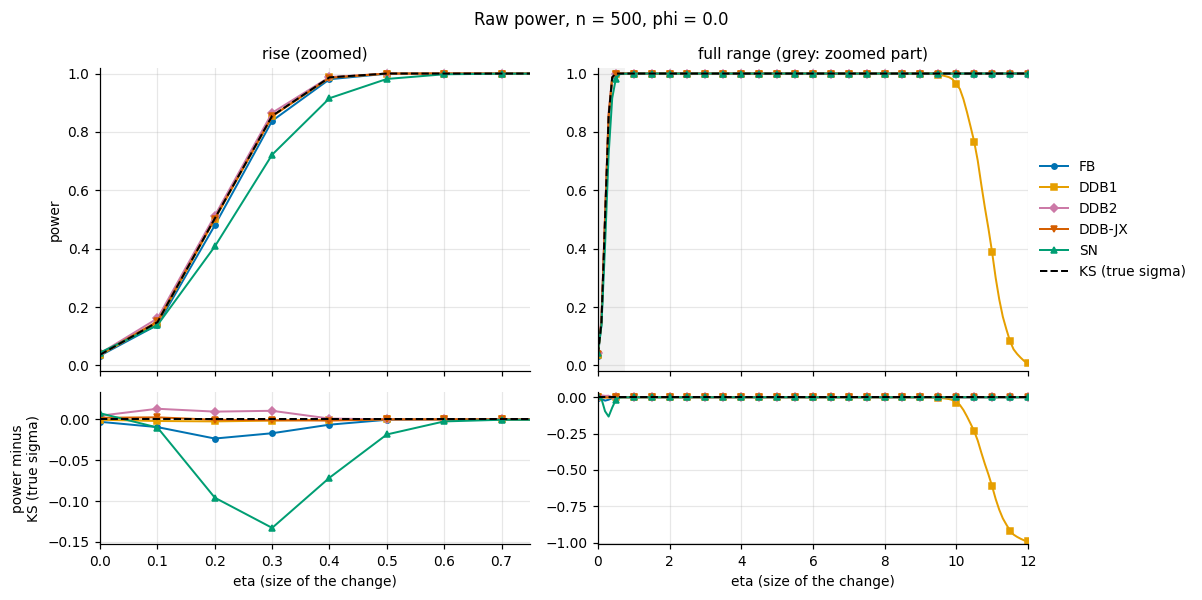

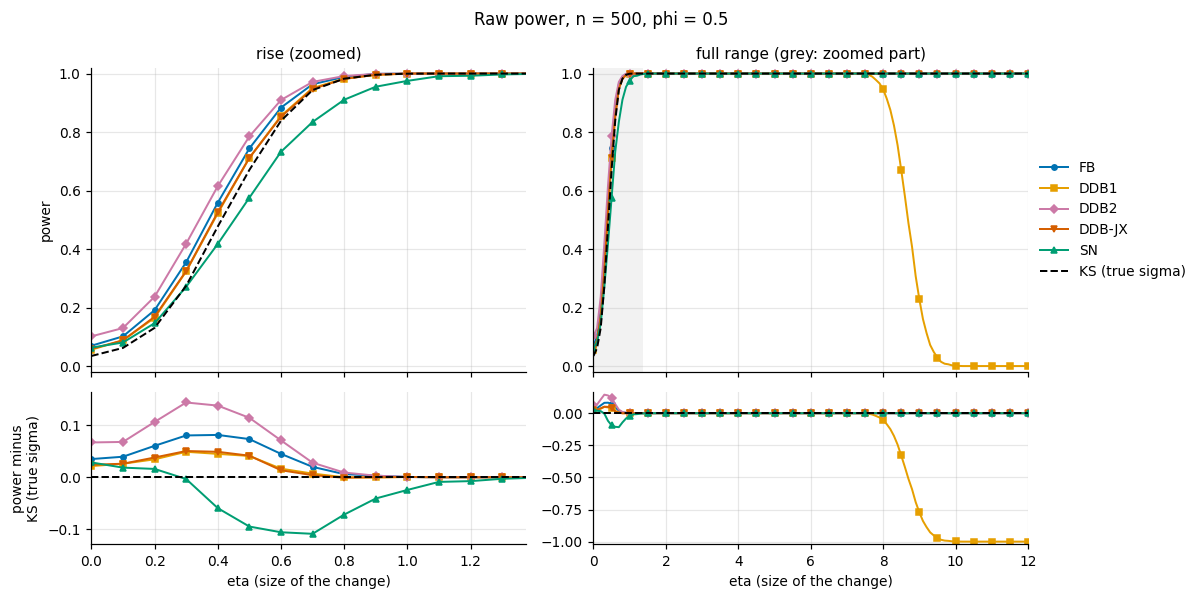

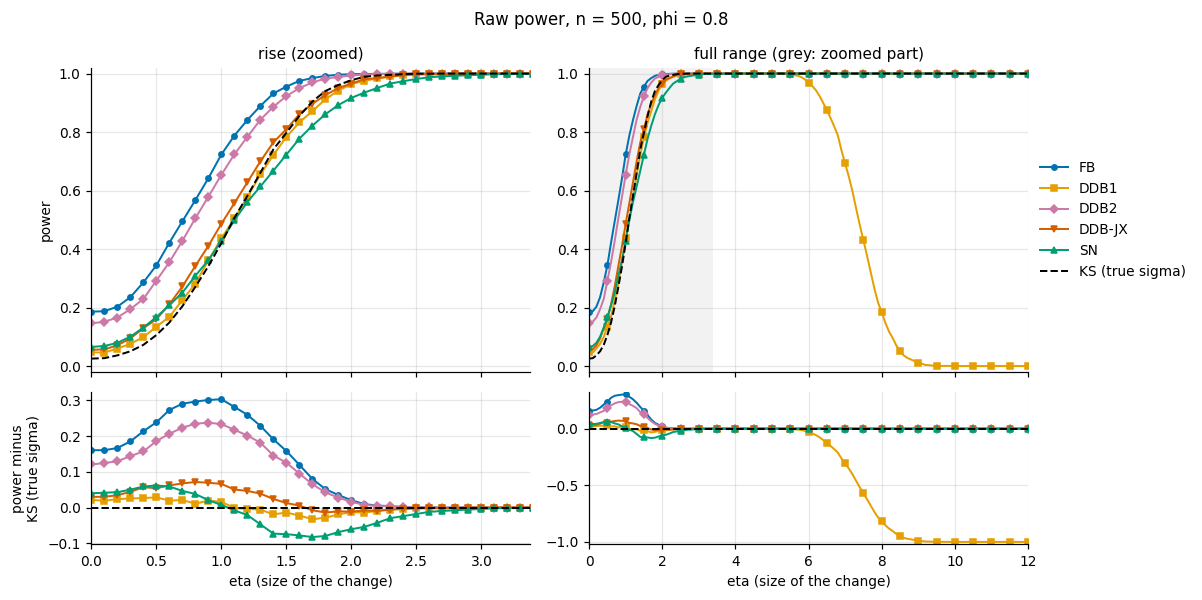

In [7]:
# Tests whose power falls to zero for large eta in some designs.
FALLING = ('DDB1', 'DDB-JX')


def rise_end(curve):
    """First eta at which every test not in FALLING has power >= 0.99."""
    lowest = np.min([curve[m] for m in tests if m not in FALLING], axis=0)
    done = np.flatnonzero(lowest >= 0.99)
    return etas[done[0]] if done.size else etas[-1]


def gap_limits(gaps, shown, tests):
    lo = min(gaps[m][shown].min() for m in tests)
    hi = max(gaps[m][shown].max() for m in tests)
    return lo - 0.02, hi + 0.02


def plot_power(curves, kind):
    """One figure per (n, phi).

    Left: the rise, zoomed in, where SN falls behind. Right: the whole eta
    range, where DDB1 and DDB-JX lose power. Bottom row: power minus
    KS (true sigma).
    """
    for n in ns:
        for phi in power_phis:
            curve = curves[n, phi]
            gaps = {m: np.subtract(curve[m], curve['KS (true sigma)'])
                    for m in tests}
            x_max = min(etas[-1], 1.25 * rise_end(curve))
            zoomed = etas <= x_max + 1e-9

            fig, axes = plt.subplots(
                2, 2, figsize=(11, 5.5), sharex='col',
                gridspec_kw={'height_ratios': [3, 1.5]})
            left, right = axes[:, 0], axes[:, 1]
            for m in tests:
                left[0].plot(etas, curve[m], **STYLE[m])
                left[1].plot(etas, gaps[m], **STYLE[m])
                right[0].plot(etas, curve[m], label=m, markevery=5,
                              **STYLE[m])
                right[1].plot(etas, gaps[m], markevery=5, **STYLE[m])

            left[0].set_title('rise (zoomed)')
            left[1].set_xlim(0, x_max)
            # DDB1 and DDB-JX are left out of this range so that their collapse
            # does not squash the other gaps. Both are shown in full on
            # the right.
            others = [m for m in tests if m not in FALLING]
            left[1].set_ylim(gap_limits(gaps, zoomed, others))
            right[0].set_title('full range (grey: zoomed part)')
            right[0].axvspan(0, x_max, color='gray', alpha=0.1, lw=0)
            right[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
            right[1].set_xlim(0, etas[-1])
            right[1].set_ylim(gap_limits(gaps, etas >= 0, tests))

            for ax in axes[0]:
                ax.set_ylim(-0.02, 1.02)
            for ax in axes[1]:
                ax.set_xlabel('eta (size of the change)')
            left[0].set_ylabel('power')
            left[1].set_ylabel('power minus\nKS (true sigma)')
            fig.suptitle(f'{kind} power, n = {n}, phi = {phi}')
            plt.tight_layout()
            name = kind.lower().replace('-', '_')
            fig.savefig(PLOTS / f'power_{name}_n{n}_phi{phi}.png')
            plt.show()


plot_power(raw_power, 'Raw')

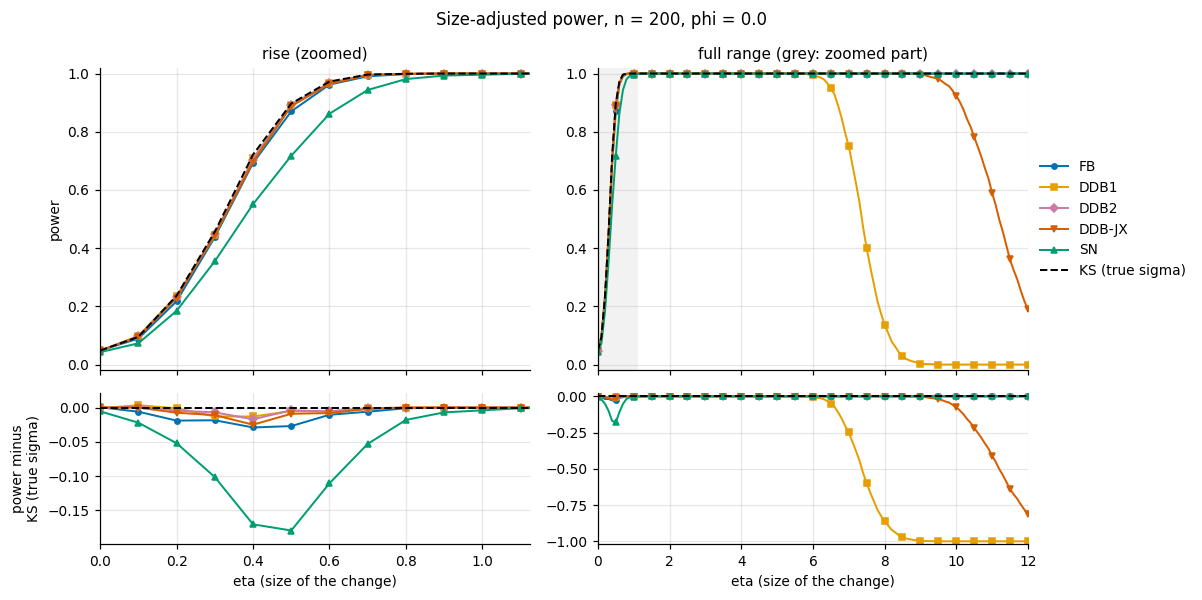

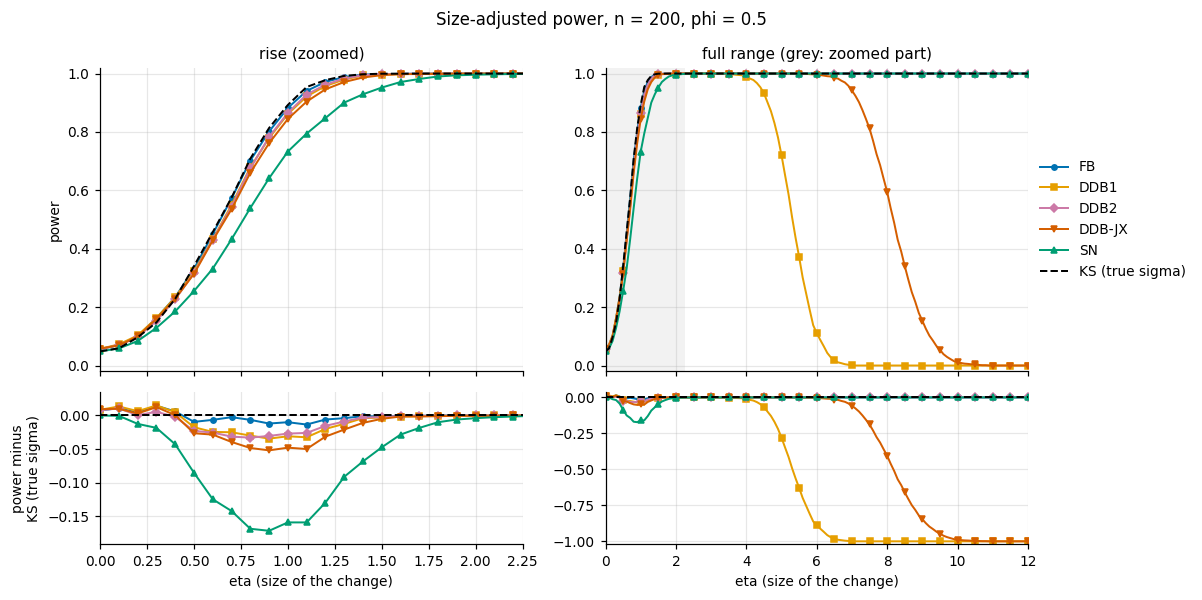

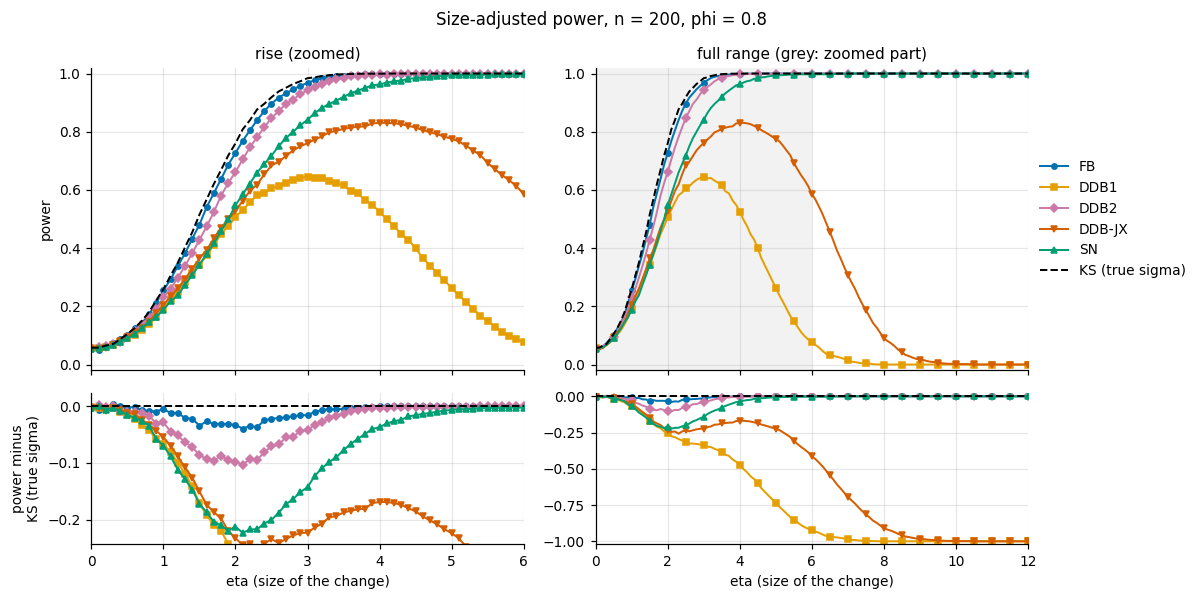

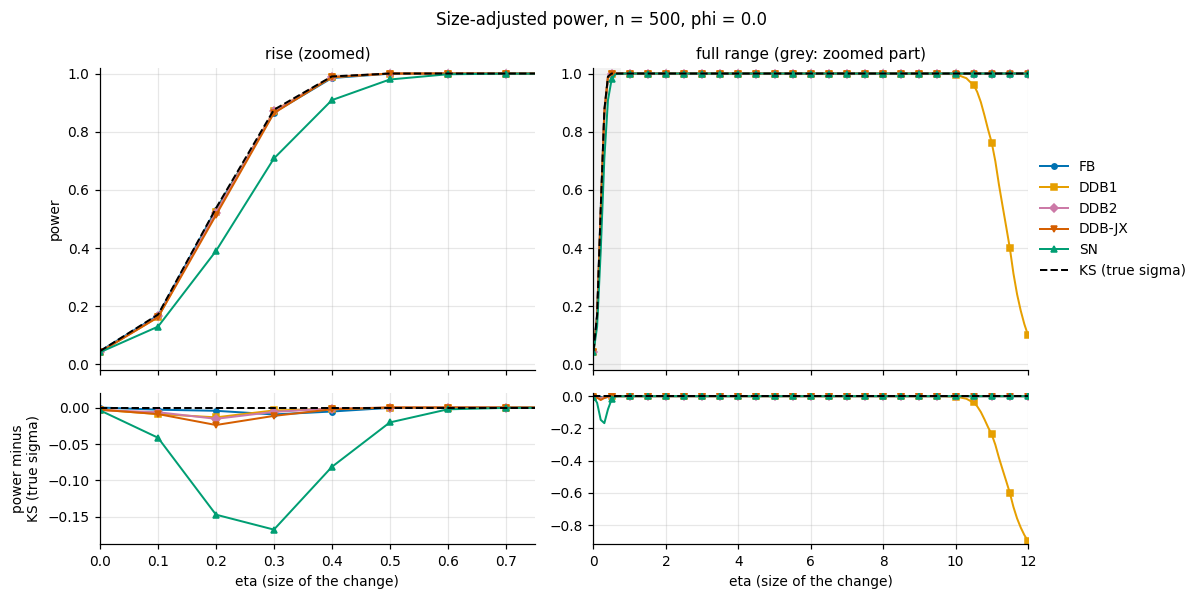

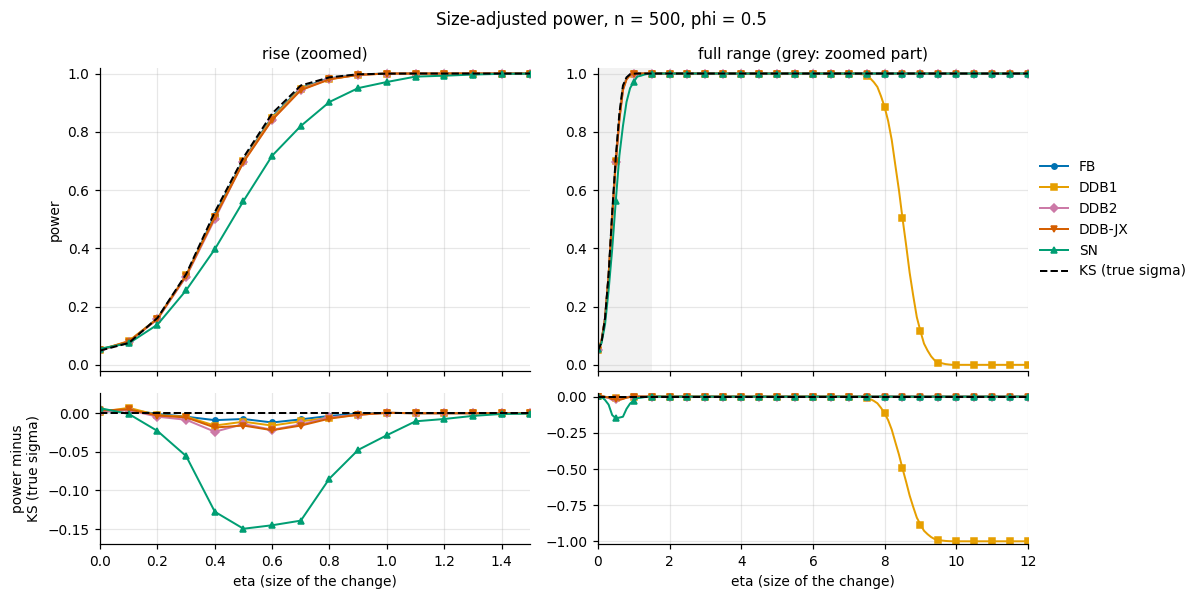

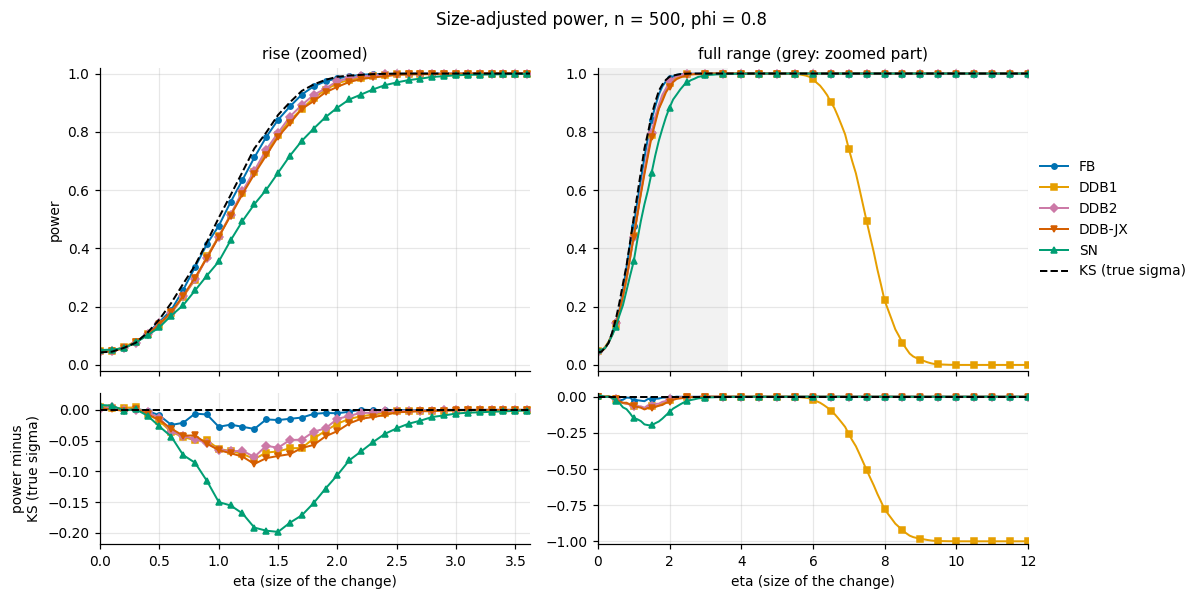

In [8]:
plot_power(power, 'Size-adjusted')

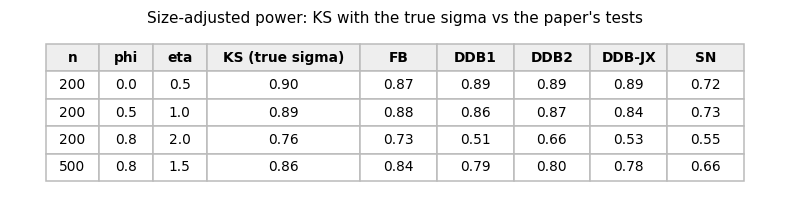

In [9]:
# Size-adjusted power at a few points in the middle of the curves.
points = [(200, 0.0, 0.5), (200, 0.5, 1.0), (200, 0.8, 2.0), (500, 0.8, 1.5)]
cols = ['KS (true sigma)', 'FB', 'DDB1', 'DDB2', 'DDB-JX', 'SN']
rows = []
for n, phi, eta in points:
    i = np.argmin(np.abs(etas - eta))
    rows.append([str(n), str(phi), str(eta)]
                + [f'{power[n, phi][m][i]:.2f}' for m in cols])

fig, ax = plt.subplots(figsize=(9, 1.9))
ax.axis('off')
table = ax.table(cellText=rows, colLabels=['n', 'phi', 'eta'] + cols,
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
widths = [0.07, 0.07, 0.07, 0.2, 0.1, 0.1, 0.1, 0.1, 0.1]
for (r, c), cell in table.get_celld().items():
    cell.set_width(widths[c])
    cell.set_height(0.17)
    cell.set_edgecolor('#bbbbbb')
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#eeeeee')
ax.set_title("Size-adjusted power: KS with the true sigma vs the paper's "
             'tests')
fig.savefig(PLOTS / 'table_size_adjusted_power.png')
plt.show()